# Fitting PyroPPI to the RAD51 paralog matrix

PPI Recorder reads an interaction out of a base editor.
The bait is fused to ABE8e, the prey to MCP, and both are expressed with a barcoded reporter RNA carrying an MS2 hairpin that MCP binds.
When bait and prey come together the editor sits beside the reporter long enough to convert adenines to inosines.
One pair in one sample is two integers: reporter reads recovered, and how many carried an edit.

PyroPPI models the log-odds of editing as a baseline for the pair, a shift per drug or condition, and a shift for the cell line.
Every part is estimated per pair and partially pooled, so a pair seen in few reads is pulled toward the rest of the screen.

Here: load the counts, fit, rank the pairs, call interactions against negative controls, read the drug and cell terms.
`rad51x9.py` does the same from a terminal and writes the figures as PNGs.

`pip install -e '.[notebooks]'` from the repository root, then run below.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

import pyroppi
from pyroppi import stats

BLUE = "#0072B2"
VERMILLION = "#D55E00"
GREEN = "#009E73"
AMBER = "#E69F00"
GREY = "#6F6F6F"
PALE = "#D9D9D9"
HEAT = LinearSegmentedColormap.from_list("ppi_recorder", ["#F7F7F7", "#9ECAE1", BLUE, "#08306B"])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "legend.frameon": False,
    "figure.dpi": 140,
})

## The data

`counts.csv` has one row per sample and measured pair: bait, prey, total reporter reads, edited reads.
`samples.csv` has one row per sample, descriptive columns followed by the binary indicators that make up the design.

This dataset is the nine-protein RAD51 paralog matrix.
Seven are recombination machinery: RAD51, its paralogs RAD51B, RAD51C, RAD51D, XRCC2 and XRCC3, and the accessory factor SFR1.
GFP and mCherry are the negative controls.
Every protein was measured against every other in both orientations, in two cell lines, with rapamycin for 0, 1 or 3 hours before harvest.

In [2]:
here = Path.cwd()
repo = next(p for p in [here, *here.parents] if (p / "data" / "rad51x9").is_dir())
counts, samples = pyroppi.read_dataset(repo / "data" / "rad51x9")

print(f"{len(counts)} rows")
print(f"{len(samples)} samples")
print(f"{counts.groupby(['bait', 'prey']).ngroups} measured pairs")
counts.head()

972 rows
12 samples
81 measured pairs


,sample,bait,prey,total,edited
0,HCT_RAD51x9_RepA_0h,GFP,GFP,34576,3351
1,HCT_RAD51x9_RepA_0h,mCherry,GFP,20811,1097
2,HCT_RAD51x9_RepA_0h,RAD51,GFP,28079,2142
3,HCT_RAD51x9_RepA_0h,RAD51B,GFP,20620,741
4,HCT_RAD51x9_RepA_0h,RAD51C,GFP,10854,768


`1h` and `3h` mark rapamycin before harvest; `HCT` marks the HCT116 samples.
`HCT_x_1h` and `HCT_x_3h` are their products, letting the rapamycin response differ between cell lines rather than forcing one shared value.
All indicators at zero is U2OS without rapamycin, the reference condition the pair baseline describes.

In [3]:
samples

,sample,cell_line,treatment,replicate,1h,3h,HCT_x_1h,HCT_x_3h,HCT
0,HCT_RAD51x9_RepA_0h,HCT116,rapamycin_0h,A,0,0,0,0,1
1,HCT_RAD51x9_RepA_1h,HCT116,rapamycin_1h,A,1,0,1,0,1
2,HCT_RAD51x9_RepA_3h,HCT116,rapamycin_3h,A,0,1,0,1,1
3,HCT_RAD51x9_RepB_0h,HCT116,rapamycin_0h,B,0,0,0,0,1
4,HCT_RAD51x9_RepB_1h,HCT116,rapamycin_1h,B,1,0,1,0,1
5,HCT_RAD51x9_RepB_3h,HCT116,rapamycin_3h,B,0,1,0,1,1
6,U2OS_RAD51x9_RepA_0h,U2OS,rapamycin_0h,A,0,0,0,0,0
7,U2OS_RAD51x9_RepA_1h,U2OS,rapamycin_1h,A,1,0,0,0,0
8,U2OS_RAD51x9_RepA_3h,U2OS,rapamycin_3h,A,0,1,0,0,0
9,U2OS_RAD51x9_RepB_0h,U2OS,rapamycin_0h,B,0,0,0,0,0


Raw edit fractions for XRCC2 as prey against four baits, one row per sample.
RAD51D, XRCC2's partner in BCDX2, edits several times harder than the controls, and every bait edits harder with rapamycin.

In [4]:
fraction = counts.assign(edit_fraction=counts.edited / counts.total)
(
    fraction[fraction.prey == "XRCC2"]
    .pivot_table(index="sample", columns="bait", values="edit_fraction")
    [["RAD51D", "RAD51C", "GFP", "mCherry"]]
    .round(3)
)

bait,RAD51D,RAD51C,GFP,mCherry
sample,,,,
HCT_RAD51x9_RepA_0h,0.145,0.056,0.073,0.056
HCT_RAD51x9_RepA_1h,0.265,0.133,0.201,0.118
HCT_RAD51x9_RepA_3h,0.302,0.158,0.248,0.183
HCT_RAD51x9_RepB_0h,0.144,0.054,0.078,0.055
HCT_RAD51x9_RepB_1h,0.259,0.124,0.174,0.112
HCT_RAD51x9_RepB_3h,0.298,0.163,0.226,0.165
U2OS_RAD51x9_RepA_0h,0.090,0.016,0.020,0.009
U2OS_RAD51x9_RepA_1h,0.199,0.047,0.068,0.035
U2OS_RAD51x9_RepA_3h,0.248,0.075,0.094,0.050


## Fitting the model

`pyroppi.fit` takes the two tables and the indicator columns making up each block.
The drug block holds the two rapamycin durations and the two cell-line interactions; the cell block holds the HCT116 indicator.

Bait and prey collapse into unordered canonical pairs, so RAD51D-XRCC2 and XRCC2-RAD51D share one estimate and 81 measured pairs become 45.
Observations under `min_reads`, 20 by default, leave the likelihood rather than the table.
Inference is stochastic variational with a mean-field normal approximation rather than MCMC, which fits a screen this size in under two minutes on a CPU.

The progress bar is suppressed here. Timing below is CPU-only.

In [5]:
%%capture
start = time.perf_counter()
result = pyroppi.fit(
    counts,
    samples,
    drug=["1h", "3h", "HCT_x_1h", "HCT_x_3h"],
    cell=["HCT"],
    num_steps=30_000,
)
elapsed = time.perf_counter() - start

In [6]:
print(f"fitted in {elapsed:.0f} s")
print(f"{len(result.canonical)} canonical pairs from {len(result.measured)} measured pairs")
print(f"{result.counts.used.sum()} of {len(result.counts)} observations above the read floor")
print(f"final ELBO loss {result.losses[-1]:,.0f}")

fitted in 91 s
45 canonical pairs from 81 measured pairs
972 of 972 observations above the read floor
final ELBO loss 70,293


### Did it converge?

Variational inference minimises the ELBO, so the check is that the loss has levelled off.
It drops by more than an order of magnitude in the first few thousand steps and is flat after.
Enlarged, the last fifth is noisy, because each step draws a fresh sample from the approximating distribution, and still creeps down by a few tens of units out of seventy thousand.
That is about a tenth of a per cent, which is what a converged variational fit looks like.
A trace still falling steeply at the last step needs more steps.

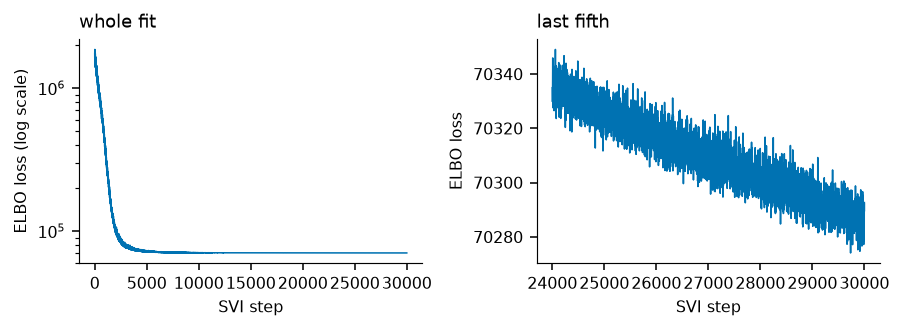

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(6.5, 2.4))
step = np.arange(1, len(result.losses) + 1)

left.plot(step, result.losses, color=BLUE, lw=0.8)
left.set_yscale("log")
left.set_xlabel("SVI step")
left.set_ylabel("ELBO loss (log scale)")
left.set_title("whole fit", loc="left")

tail = slice(int(0.8 * len(result.losses)), None)
right.plot(step[tail], result.losses[tail], color=BLUE, lw=0.8)
right.set_xlabel("SVI step")
right.set_ylabel("ELBO loss")
right.set_title("last fifth", loc="left")

fig.tight_layout()

## Ranking the pairs

`result.pairs()` returns one row per canonical pair.
`propensity_mean` is the pair's baseline through the logistic function, on the scale of an editing probability: the fraction of reporter reads expected for that pair in the reference condition, here U2OS without rapamycin.
`logit_mean` is the same quantity on the log-odds scale, and is what the statistics below use.

In [8]:
pairs = result.pairs()
pairs["pair"] = np.where(
    pairs.protein_a == pairs.protein_b,
    pairs.protein_a,
    pairs.protein_a + "-" + pairs.protein_b,
)
columns = ["pair", "logit_mean", "propensity_mean", "propensity_q05", "propensity_q95"]
pairs.sort_values("propensity_mean", ascending=False)[columns].head(10).round(4)

,pair,logit_mean,propensity_mean,propensity_q05,propensity_q95
32,RAD51D-XRCC2,-1.8134,0.1402,0.1395,0.1409
28,RAD51C-XRCC3,-2.1345,0.1058,0.1048,0.1068
18,RAD51B-RAD51C,-2.8593,0.0542,0.0537,0.0548
8,GFP-mCherry,-3.2855,0.0361,0.0359,0.0363
0,GFP,-3.3394,0.0342,0.0340,0.0344
25,RAD51C-RAD51D,-3.3920,0.0325,0.0322,0.0329
34,RAD51D-mCherry,-3.4360,0.0312,0.0310,0.0314
4,GFP-RAD51D,-3.4687,0.0302,0.0300,0.0304
9,RAD51,-3.4834,0.0298,0.0295,0.0301
15,RAD51-XRCC3,-3.4946,0.0295,0.0292,0.0297


## Calling the hits

GFP and mCherry supply the cut.
They are inert proteins outside this machinery, so a pair with either at one end should not interact.
Seventeen of the 45 canonical pairs have a control at one end, and their spread on the log-odds scale is the null for the other 28.

`stats.control_test` returns those 28 with a z-score and a one-tailed p-value.
`stats.control_threshold` gives the same cut as a propensity, the 95th percentile of the control distribution, for drawing on a figure.

In [9]:
tested = stats.control_test(pairs, controls=("GFP", "mCherry"))
threshold = stats.control_threshold(pairs, controls=("GFP", "mCherry"), q=0.95)
pairs["hit"] = pairs.index.isin(tested.index[tested.p < 0.05])

print(f"control threshold: {threshold:.4f}, i.e. {threshold * 100:.2f}% of reads edited")
print(f"{pairs.hit.sum()} of {len(tested)} non-control pairs called at p < 0.05")

called = tested.assign(pair=pairs.loc[tested.index, "pair"]).sort_values("p").head(6)
called["p"] = called.p.map("{:.2g}".format)
called[["pair", "propensity_mean", "z", "p"]].round(4)

control threshold: 0.0400, i.e. 4.00% of reads edited
3 of 28 non-control pairs called at p < 0.05


,pair,propensity_mean,z,p
32,RAD51D-XRCC2,0.1402,5.2893,6.1e-08
28,RAD51C-XRCC3,0.1058,4.4317,4.7e-06
18,RAD51B-RAD51C,0.0542,2.4957,0.0063
25,RAD51C-RAD51D,0.0325,1.0728,0.14
9,RAD51,0.0298,0.8286,0.2
15,RAD51-XRCC3,0.0295,0.7988,0.21


Three pairs clear the controls: RAD51D-XRCC2 at 14.0% of reads edited, RAD51C-XRCC3 at 10.6%, RAD51B-RAD51C at 5.4%, against a threshold of 4.0%.
RAD51B-RAD51C and RAD51D-XRCC2 are the two halves of BCDX2; RAD51C-XRCC3 is CX3.
All three have been seen by co-immunoprecipitation, yeast two-hybrid, reconstitution with purified protein and proximity labelling.
The next pair down, RAD51C-RAD51D, is the junction joining the halves of BCDX2, and sits under the threshold at 3.3%.

### The matrix

The model collapses bait and prey into one canonical pair, so the nine-by-nine matrix is symmetric by construction.
Keeping the controls inside it makes the comparison direct: the three called pairs are the only cells standing out of a flat background, and the GFP and mCherry rows are part of that background.

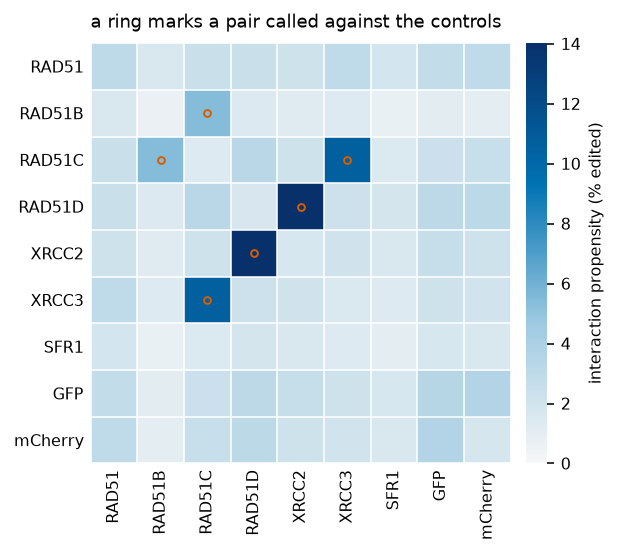

In [10]:
order = ["RAD51", "RAD51B", "RAD51C", "RAD51D", "XRCC2", "XRCC3", "SFR1", "GFP", "mCherry"]
propensity, called = {}, set()
for _, row in pairs.iterrows():
    for key in [(row.protein_a, row.protein_b), (row.protein_b, row.protein_a)]:
        propensity[key] = row.propensity_mean
        if row.hit:
            called.add(key)
grid = np.array([[propensity[(a, b)] for b in order] for a in order])

fig, ax = plt.subplots(figsize=(4.6, 4.0))
image = ax.imshow(grid * 100, cmap=HEAT, vmin=0)
ax.set_xticks(range(len(order)), order, rotation=90)
ax.set_yticks(range(len(order)), order)
ax.set_xticks(np.arange(len(order) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(order) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="white", lw=0.8)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
for i, a in enumerate(order):
    for j, b in enumerate(order):
        if (a, b) in called:
            ax.plot(j, i, marker="o", ms=3.5, mfc="none", mec=VERMILLION, mew=1.0)

bar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.03)
bar.set_label("interaction propensity (% edited)")
bar.outline.set_visible(False)
ax.set_title("a ring marks a pair called against the controls", loc="left", pad=8)
fig.tight_layout()

### The ranking

The three called pairs sit well clear of the threshold.
The controls sit mid-pack rather than at the bottom, and everything else is indistinguishable from them.
Editing is never zero, so the control level is the assay background, and most non-control pairs here do not interact either.

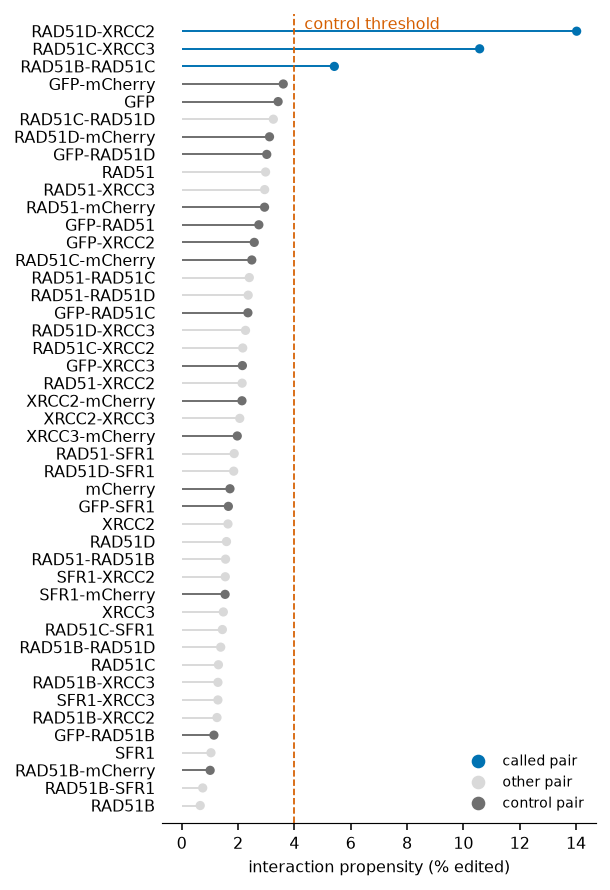

In [11]:
ranked = pairs.sort_values("propensity_mean").reset_index(drop=True)
is_control = ranked.protein_a.isin(["GFP", "mCherry"]) | ranked.protein_b.isin(["GFP", "mCherry"])
colour = np.where(is_control, GREY, np.where(ranked.hit, BLUE, PALE))

fig, ax = plt.subplots(figsize=(4.4, 6.4))
y = np.arange(len(ranked))
ax.hlines(y, 0, ranked.propensity_mean * 100, color=colour, lw=1.0)
ax.scatter(ranked.propensity_mean * 100, y, c=colour, s=14, zorder=3)
ax.axvline(threshold * 100, color=VERMILLION, ls="--", lw=0.9)
ax.text(threshold * 100, len(ranked) - 0.2, "  control threshold", color=VERMILLION, va="top")
ax.set_yticks(y, ranked.pair)
ax.set_ylim(-1, len(ranked))
ax.set_xlabel("interaction propensity (% edited)")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(
    handles=[
        plt.Line2D([], [], marker="o", ls="", color=BLUE, label="called pair"),
        plt.Line2D([], [], marker="o", ls="", color=PALE, label="other pair"),
        plt.Line2D([], [], marker="o", ls="", color=GREY, label="control pair"),
    ],
    loc="lower right",
    fontsize=7,
)
fig.tight_layout()

## The drug and cell terms

`result.effects()` returns the other two blocks: one row per covariate per canonical pair, with the shift it adds on the log-odds scale.

In [12]:
effects = result.effects()
order_cov = ["1h", "3h", "HCT_x_1h", "HCT_x_3h", "HCT"]
effects.groupby("covariate").logit_mean.agg(["mean", "min", "max"]).loc[order_cov].round(3)

,mean,min,max
covariate,,,
1h,1.225,0.669,1.657
3h,1.668,0.929,2.161
HCT_x_1h,-0.320,-0.677,0.013
HCT_x_3h,-0.394,-0.798,-0.090
HCT,1.017,0.086,1.436


Rapamycin raises editing across the board.
All 45 canonical pairs have a positive shift at both durations, controls included, and the average shift is larger at three hours.
The rise covers the whole matrix rather than the interacting pairs alone, so rapamycin lifts background along with signal.
Both interaction terms are negative on average, so the same treatment buys less extra editing in HCT116 than U2OS, while `HCT` is positive for every pair, so HCT116 edits higher without the drug.

### How the three blocks add up

The blocks are additive on the log-odds scale, which is awkward to reason about, so PyroPPI reports them as increments of the editing probability.
Taking the logistic one block at a time gives three pieces that sum to the fitted mean:

```
a  = sigmoid(pair)
b  = sigmoid(pair + drug)
mu = sigmoid(pair + drug + cell)

pair increment = a      drug increment = b - a      cell increment = mu - b
```

`result.contributions()` returns that split for every observation alongside the reads it was fitted to.
The right panel shows one HCT116 sample at three hours: blue is the interaction, amber what the treatment adds, green what the cell line adds, and the black point what was observed.
Pairs measured in both orientations give two identical bars, since the model shares one estimate, while their observed points differ as separate measurements.

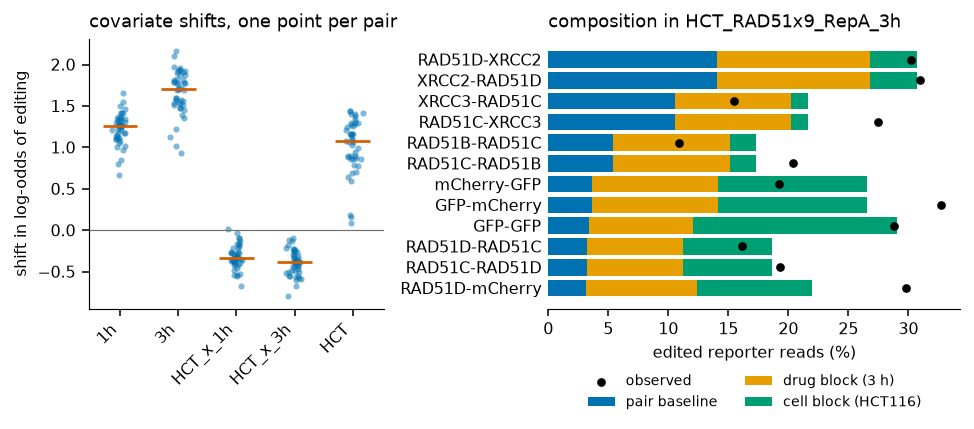

In [13]:
sample = "HCT_RAD51x9_RepA_3h"
parts = result.contributions()
parts = parts[parts["sample"] == sample].sort_values("contrib_pair", ascending=False).head(12)[::-1]

fig, (left, right) = plt.subplots(1, 2, figsize=(7.0, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})

jitter = np.random.default_rng(0)
for x, name in enumerate(order_cov):
    values = effects.loc[effects.covariate == name, "logit_mean"]
    left.scatter(x + jitter.normal(0, 0.06, len(values)), values, s=10, color=BLUE, alpha=0.5, lw=0)
    left.hlines(values.median(), x - 0.3, x + 0.3, color=VERMILLION, lw=1.4)
left.axhline(0, color=GREY, lw=0.6)
left.set_xticks(range(len(order_cov)), order_cov, rotation=45, ha="right")
left.set_ylabel("shift in log-odds of editing")
left.set_title("covariate shifts, one point per pair", loc="left")

y = np.arange(len(parts))
pair_pct, drug_pct, cell_pct = (
    parts[c] * 100 for c in ["contrib_pair", "contrib_drug", "contrib_cell"])
right.barh(y, pair_pct, color=BLUE, label="pair baseline")
right.barh(y, drug_pct, left=pair_pct, color=AMBER, label="drug block (3 h)")
right.barh(y, cell_pct, left=pair_pct + drug_pct, color=GREEN, label="cell block (HCT116)")
right.scatter(parts.edited / parts.total * 100, y, color="black", s=12, zorder=3, label="observed")
right.set_yticks(y, [f"{b}-{p}" for b, p in zip(parts.bait, parts.prey)])
right.set_xlabel("edited reporter reads (%)")
right.set_title(f"composition in {sample}", loc="left")
right.tick_params(axis="y", length=0)
right.spines["left"].set_visible(False)
right.legend(fontsize=7, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.42))

fig.tight_layout()

The bars do not land on every observed point.
Each is one pair's estimate pooled over twelve samples and both orientations, so it sits where the whole screen puts the pair.

## Next

`result.save(directory)` writes the pair table, effects, per-observation contributions, posterior draws and loss trace; `pyroppi.load_fit(directory)` reads them back, so a figure does not need a refit.

The same three calls run every dataset in `data/`.
A screen of variants of one protein swaps the control test for `stats.synonymous_test`, using synonymous substitutions as the null.
A screen where every sample is treated has no untreated reference, and is fitted with `baseline=False`.
`scripts/fit_all.py` runs the whole set.